<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 3: KNN, Logistic Regression, LDA & Linear Regression**

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Classification algorithms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Regression algorithms
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    classification_report,

    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


##### **1. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement KNN classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

In [ ]:
# Loading the classification dataset
from google.colab import files
uploaded = files.upload()

campus_df = pd.read_csv('campus_preprocessed.csv')
print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed.csv
Dataset loaded successfully!


In [ ]:
display(campus_df.head())

# Dataset Size
print("Number of Instances:", campus_df.shape[0])
print("Number of Attributes:", campus_df.shape[1])
print("Dataset Size:", campus_df.shape)
print("Memory occupied:", (round(campus_df.memory_usage(deep=True).sum() / (1024**2), 2), "MB"))


,age,ssc_percentage,hsc_percentage,degree_percentage,mba_percentage,internships_count,projects_count,certifications_count,technical_skills_score,soft_skills_score,...,hsc_board_State,hsc_stream_Commerce,hsc_stream_Science,degree_field_Business,degree_field_Engineering,degree_field_Other,degree_field_Science,specialization_Marketing & Finance,specialization_Marketing & HR,specialization_Not Applicable
0,22,71.01,76.76,64.44,0.0,1,2,2,6.8,7.8,...,0,1,0,0,1,0,0,0,0,1
1,22,58.46,57.62,68.24,0.0,1,1,2,4.6,4.8,...,1,0,1,1,0,0,0,0,0,1
2,21,67.83,65.67,52.33,0.0,4,3,2,4.7,5.0,...,1,1,0,0,1,0,0,0,0,1
3,21,80.40,77.15,56.55,0.0,2,3,3,6.8,7.6,...,1,0,1,0,1,0,0,0,0,1
4,21,66.10,62.81,78.93,0.0,1,4,2,7.0,5.7,...,0,0,1,0,1,0,0,0,0,1


Number of Instances: 100000
Number of Attributes: 34
Dataset Size: (100000, 34)
Memory occupied: (np.float64(25.94), 'MB')


In [ ]:
# Dataset information
campus_df.info()

# Check missing values
print("\nMissing Values:")
print(campus_df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(campus_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   age                                 100000 non-null  int64  
 1   ssc_percentage                      100000 non-null  float64
 2   hsc_percentage                      100000 non-null  float64
 3   degree_percentage                   100000 non-null  float64
 4   mba_percentage                      100000 non-null  float64
 5   internships_count                   100000 non-null  int64  
 6   projects_count                      100000 non-null  int64  
 7   certifications_count                100000 non-null  int64  
 8   technical_skills_score              100000 non-null  float64
 9   soft_skills_score                   100000 non-null  float64
 10  aptitude_score                      100000 non-null  float64
 11  communication_score        

,age,ssc_percentage,hsc_percentage,degree_percentage,mba_percentage,internships_count,projects_count,certifications_count,technical_skills_score,soft_skills_score,...,hsc_board_State,hsc_stream_Commerce,hsc_stream_Science,degree_field_Business,degree_field_Engineering,degree_field_Other,degree_field_Science,specialization_Marketing & Finance,specialization_Marketing & HR,specialization_Not Applicable
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000
mean,21.55581,71.929885,71.831667,70.185520,22.853134,1.677490,3.295290,1.896330,5.982618,6.413043,...,0.500000,0.350490,0.497710,0.249460,0.400190,0.101470,0.148760,0.116190,0.11741,0.649650
std,1.50696,11.867225,13.903709,15.599274,31.610435,1.306627,1.870414,1.775324,1.948801,2.292634,...,0.500003,0.477126,0.499997,0.432703,0.489939,0.301952,0.355854,0.320454,0.32191,0.477082
min,18.00000,40.000000,40.000000,45.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,21.00000,63.870000,62.120000,58.090000,0.000000,1.000000,2.000000,0.000000,4.600000,4.800000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
50%,21.00000,71.920000,71.860000,69.890000,0.000000,1.000000,3.000000,1.000000,6.000000,6.500000,...,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1.000000
75%,22.00000,80.030000,81.720000,81.840000,59.330000,2.000000,4.000000,3.000000,7.300000,8.200000,...,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,1.000000
max,26.00000,100.000000,100.000000,100.000000,100.000000,5.000000,10.000000,8.000000,10.000000,10.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000


In [ ]:
# Check for non-numerical columns
non_numerical_columns = campus_df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Non-Numerical Columns:", non_numerical_columns)

# Check duplicate records
print("Duplicate Records:", campus_df.duplicated().sum())

# Check target distribution
print("\nTarget Class Distribution:")
print(campus_df['placed'].value_counts())

print("\nTarget Class Percentages:")
print(campus_df['placed'].value_counts(normalize=True) * 100)

Non-Numerical Columns: []
Duplicate Records: 0

Target Class Distribution:
placed
1    84432
0    15568
Name: count, dtype: int64

Target Class Percentages:
placed
1    84.432
0    15.568
Name: proportion, dtype: float64


In [ ]:
# Separate independent and dependent variables
X = campus_df.drop(columns=['placed'])
y = campus_df['placed']

print("Independent Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Independent Features Shape: (100000, 33)
Target Variable Shape: (100000,)


In [ ]:
# Splitting the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Displaying the shapes of the resulting datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Dataset Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")
print("Testing Dataset Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Features: (80000, 33)
Testing Features: (20000, 33)
Training Target: (80000,)
Testing Target: (20000,)

Training Dataset Percentage: 80.0 %
Testing Dataset Percentage: 20.0 %


In [ ]:
# Feature Scaling

# Initializing StandardScaler
scaler = StandardScaler()

# Fitting the scaler on training data and transforming it
X_train_scaled = scaler.fit_transform(X_train)

# Transforming testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (80000, 33)
Scaled Testing Shape: (20000, 33)


### Implementation of KNN Classifier

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification. It classifies a new data point based on the majority class among its K nearest neighbors.

The distance between data points is calculated using a distance metric such as Euclidean distance.

In this implementation, K is initially selected as 5. Feature scaling is applied because KNN is distance-based and features with larger numerical ranges could otherwise dominate distance calculations.

In [ ]:
# Initialize KNN Classifier
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Classifier trained successfully!")

KNN Classifier trained successfully!


In [ ]:
# Predict target values for test data
y_pred_knn = knn_model.predict(X_test_scaled)

# Obtain predicted probabilities for positive class
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_knn[:10])

Predictions generated successfully!

First 10 Actual Values:
[1 0 1 0 1 1 1 1 1 1]

First 10 Predicted Values:
[1 0 1 1 1 1 1 1 1 1]


In [ ]:
# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, zero_division=0
)

knn_recall = recall_score(
    y_test, y_pred_knn, zero_division=0
)

knn_f1 = f1_score(
    y_test, y_pred_knn, zero_division=0
)

print("KNN CLASSIFIER PERFORMANCE")
print("-" * 40)

print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1-Score :", round(knn_f1, 4))

KNN CLASSIFIER PERFORMANCE
----------------------------------------
Accuracy : 0.8377
Precision: 0.8607
Recall   : 0.9638
F1-Score : 0.9093


Confusion Matrix:
[[  479  2635]
 [  611 16275]]


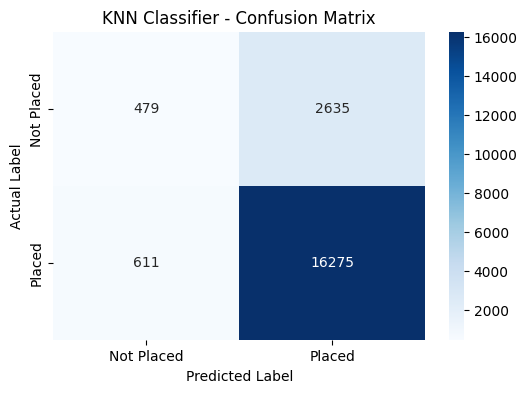

In [ ]:
# Generate confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("Confusion Matrix:")
print(cm_knn)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN Classifier - Confusion Matrix")
plt.show()

In [ ]:
# Generate detailed classification report
print("KNN Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    )
)

KNN Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.44      0.15      0.23      3114
      Placed       0.86      0.96      0.91     16886

    accuracy                           0.84     20000
   macro avg       0.65      0.56      0.57     20000
weighted avg       0.80      0.84      0.80     20000



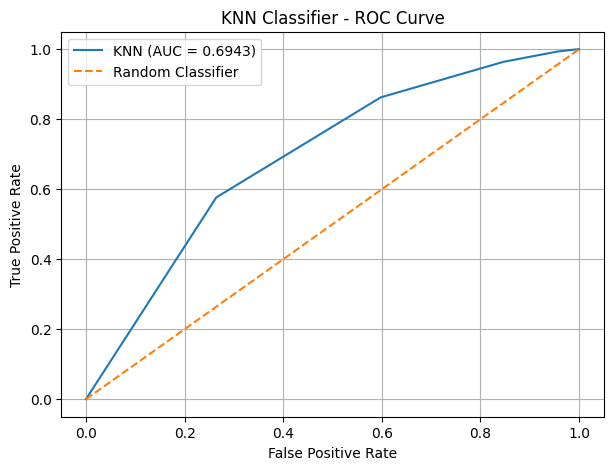

KNN AUC Score: 0.6943


In [ ]:
# Calculate False Positive Rate and True Positive Rate
fpr_knn, tpr_knn, thresholds_knn = roc_curve(
    y_test,
    y_prob_knn
)

# Calculate Area Under the Curve
auc_knn = auc(fpr_knn, tpr_knn)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f'KNN (AUC = {auc_knn:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN Classifier - ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("KNN AUC Score:", round(auc_knn, 4))

### **Conclusion – KNN Classifier**

- Achieved an accuracy of **83.77%**, indicating good overall classification performance.
- Obtained a precision of **86.07%** and recall of **96.38%** for the Placed class.
- Achieved an F1-score of **90.93%**, showing a good balance between precision and recall for the Placed class.
- Obtained a ROC-AUC score of **0.6943**, indicating moderate class discrimination.
- The model identified placed students effectively but struggled to identify students who were not placed.

##### **2. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement logistic regression classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

### Implementation of Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification problems. It estimates the probability of an observation belonging to a particular class using the logistic (sigmoid) function.

The predicted probability is converted into a class label using a classification threshold, generally 0.5.

In this implementation, Logistic Regression is used to predict whether a student will be placed or not placed.

In [ ]:
# Initialize Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict class labels
y_pred_lr = logistic_model.predict(X_test_scaled)

# Predict probabilities for positive class
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

Predictions generated successfully!

First 10 Actual Values:
[1 0 1 0 1 1 1 1 1 1]

First 10 Predicted Values:
[1 1 1 0 1 1 1 1 1 1]


In [ ]:
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test, y_pred_lr, zero_division=0
)

lr_recall = recall_score(
    y_test, y_pred_lr, zero_division=0
)

lr_f1 = f1_score(
    y_test, y_pred_lr, zero_division=0
)

print("LOGISTIC REGRESSION PERFORMANCE")
print("-" * 40)

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-Score :", round(lr_f1, 4))

LOGISTIC REGRESSION PERFORMANCE
----------------------------------------
Accuracy : 0.8586
Precision: 0.8756
Recall   : 0.9703
F1-Score : 0.9206


Confusion Matrix:
[[  787  2327]
 [  501 16385]]


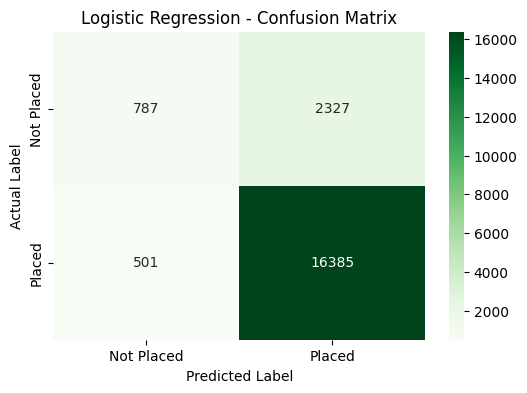

In [ ]:
# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
# Generate classification report
print("Logistic Regression Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    )
)

Logistic Regression Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.61      0.25      0.36      3114
      Placed       0.88      0.97      0.92     16886

    accuracy                           0.86     20000
   macro avg       0.74      0.61      0.64     20000
weighted avg       0.83      0.86      0.83     20000



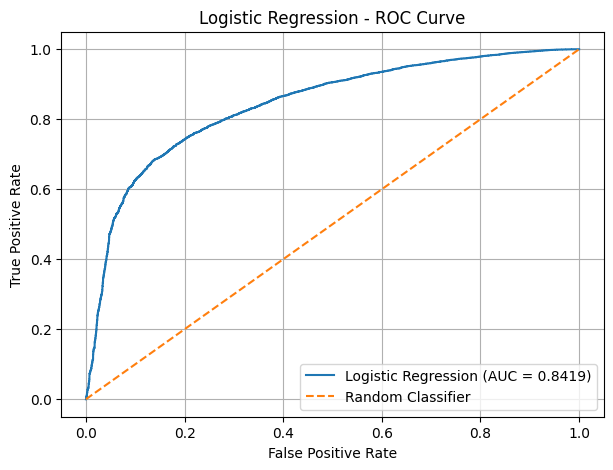

Logistic Regression AUC Score: 0.8419


In [ ]:
# Calculate ROC values
fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_test,
    y_prob_lr
)

# Calculate AUC
auc_lr = auc(fpr_lr, tpr_lr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f'Logistic Regression (AUC = {auc_lr:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("Logistic Regression AUC Score:", round(auc_lr, 4))


### **Conclusion – Logistic Regression**

- Achieved an accuracy of **85.86%**, the highest among the three classification models.
- Obtained a precision of **87.56%** and recall of **97.03%** for the Placed class.
- Achieved an F1-score of **92.06%**, indicating strong classification performance.
- Obtained a ROC-AUC score of **0.8419**, demonstrating good class discrimination.
- The model showed the best overall performance among the three classifiers, although it still struggled to identify the minority class (Not Placed).

##### **3. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement linear discriminant classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

### Implementation of Linear Discriminant Analysis

Linear Discriminant Analysis (LDA) is a supervised machine learning algorithm used for classification. It finds a linear combination of features that best separates different classes.

LDA aims to maximize the separation between class means while minimizing the variation within each class.

In this implementation, LDA is used to classify students into placed and not-placed categories.

In [ ]:
# Initialize Linear Discriminant Analysis model
lda_model = LinearDiscriminantAnalysis()

# Train the model
lda_model.fit(X_train_scaled, y_train)

print("Linear Discriminant Analysis model trained successfully!")

Linear Discriminant Analysis model trained successfully!


In [ ]:
# Predict class labels
y_pred_lda = lda_model.predict(X_test_scaled)

# Predict probabilities for positive class
y_prob_lda = lda_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lda[:10])

Predictions generated successfully!

First 10 Actual Values:
[1 0 1 0 1 1 1 1 1 1]

First 10 Predicted Values:
[1 1 1 0 1 1 1 1 1 1]


In [ ]:
# Calculate evaluation metrics
lda_accuracy = accuracy_score(y_test, y_pred_lda)

lda_precision = precision_score(
    y_test, y_pred_lda, zero_division=0
)

lda_recall = recall_score(
    y_test, y_pred_lda, zero_division=0
)

lda_f1 = f1_score(
    y_test, y_pred_lda, zero_division=0
)

print("LINEAR DISCRIMINANT ANALYSIS PERFORMANCE")
print("-" * 45)

print("Accuracy :", round(lda_accuracy, 4))
print("Precision:", round(lda_precision, 4))
print("Recall   :", round(lda_recall, 4))
print("F1-Score :", round(lda_f1, 4))

LINEAR DISCRIMINANT ANALYSIS PERFORMANCE
---------------------------------------------
Accuracy : 0.8573
Precision: 0.8762
Recall   : 0.9678
F1-Score : 0.9197


Confusion Matrix:
[[  804  2310]
 [  543 16343]]


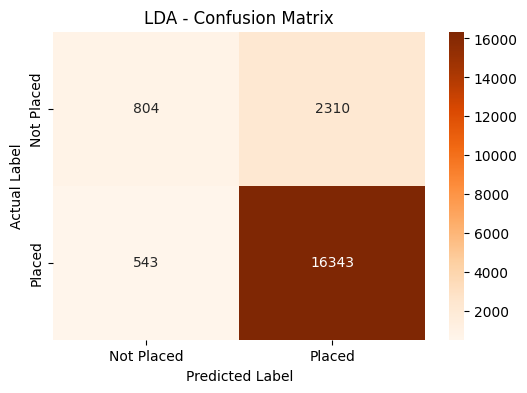

In [ ]:
# Generate confusion matrix
cm_lda = confusion_matrix(y_test, y_pred_lda)

print("Confusion Matrix:")
print(cm_lda)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lda,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LDA - Confusion Matrix")
plt.show()

In [ ]:
# Generate classification report
print("LDA Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_lda,
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    )
)

LDA Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.60      0.26      0.36      3114
      Placed       0.88      0.97      0.92     16886

    accuracy                           0.86     20000
   macro avg       0.74      0.61      0.64     20000
weighted avg       0.83      0.86      0.83     20000



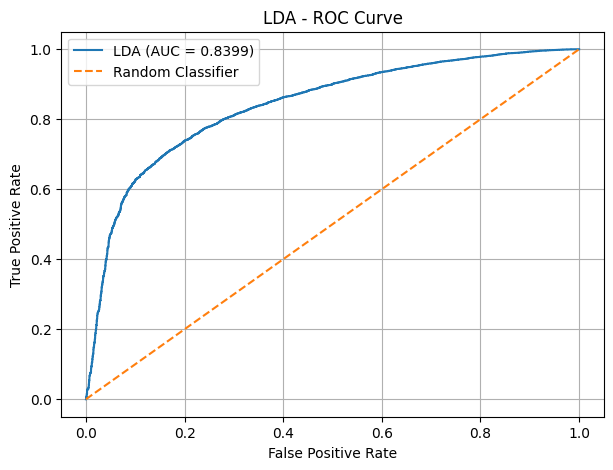

LDA AUC Score: 0.8399


In [ ]:
# Calculate ROC values
fpr_lda, tpr_lda, thresholds_lda = roc_curve(
    y_test,
    y_prob_lda
)

# Calculate AUC
auc_lda = auc(fpr_lda, tpr_lda)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_lda,
    tpr_lda,
    label=f'LDA (AUC = {auc_lda:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA - ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("LDA AUC Score:", round(auc_lda, 4))


### **Conclusion – Linear Discriminant Analysis (LDA)**

- Achieved an accuracy of **85.74%**, showing good overall classification performance.
- Obtained a precision of **87.62%** and recall of **96.78%** for the Placed class.
- Achieved an F1-score of **91.97%**, indicating a good balance between precision and recall.
- Obtained a ROC-AUC score of **0.8399**, demonstrating good class discrimination.
- The model performed very similarly to Logistic Regression but showed slightly lower accuracy, recall, F1-score, and ROC-AUC.



In [ ]:
# Create a comparison table
classification_results = pd.DataFrame({
    'Algorithm': [
        'KNN Classifier',
        'Logistic Regression',
        'Linear Discriminant Analysis'
    ],
    'Accuracy': [
        knn_accuracy,
        lr_accuracy,
        lda_accuracy
    ],
    'Precision': [
        knn_precision,
        lr_precision,
        lda_precision
    ],
    'Recall': [
        knn_recall,
        lr_recall,
        lda_recall
    ],
    'F1-Score': [
        knn_f1,
        lr_f1,
        lda_f1
    ],
    'AUC': [
        auc_knn,
        auc_lr,
        auc_lda
    ]
})

display(
    classification_results.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True)
)

,Algorithm,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,0.85860,0.875641,0.970330,0.920557,0.841934
1,Linear Discriminant Analysis,0.85735,0.876159,0.967843,0.919722,0.839904
2,KNN Classifier,0.83770,0.860656,0.963816,0.909319,0.694283



### **Overall Conclusion – Classification**

- KNN, Logistic Regression, and LDA were successfully implemented and evaluated using the same **80:20 training-testing split**.
- Their performances were compared using accuracy, precision, recall, F1-score, and ROC-AUC.
- **Logistic Regression** demonstrated the best overall performance, achieving the highest accuracy, F1-score, and ROC-AUC.
- All three models achieved high recall for the Placed class but comparatively low recall for the Not Placed class.
- This indicates that the imbalanced target distribution affected the models' ability to identify students who were not placed.


##### **4. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement KNN regressor and measures its performances such as MAE, MSE, RMSE, and R2. Give the conclusion statements according to the performances of the model.**

In [ ]:
# Loading the classification dataset
from google.colab import files
uploaded = files.upload()

uber_df = pd.read_csv('uber_preprocessed.csv')
print("Dataset loaded successfully!")

Saving uber_preprocessed.csv to uber_preprocessed.csv
Dataset loaded successfully!


In [ ]:
display(uber_df.head())

# Dataset dimensions
print("Number of Instances:", uber_df.shape[0])
print("Number of Attributes:", uber_df.shape[1])
print("Dataset Shape:", uber_df.shape)

# Memory occupied
print(
    "Memory Occupied:",
    round(uber_df.memory_usage(deep=True).sum() / (1024**2), 2),
    "MB"
)

# Dataset information
print("\nDataset Information:")
uber_df.info()

# Missing values
print("\nMissing Values:")
print(uber_df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(uber_df.describe())

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17


Number of Instances: 194918
Number of Attributes: 11
Dataset Shape: (194918, 11)
Memory Occupied: 16.36 MB

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 194918 entries, 0 to 194917
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        194918 non-null  float64
 1   pickup_longitude   194918 non-null  float64
 2   pickup_latitude    194918 non-null  float64
 3   dropoff_longitude  194918 non-null  float64
 4   dropoff_latitude   194918 non-null  float64
 5   passenger_count    194918 non-null  int64  
 6   pickup_year        194918 non-null  int64  
 7   pickup_month       194918 non-null  int64  
 8   pickup_day         194918 non-null  int64  
 9   pickup_dayofweek   194918 non-null  int64  
 10  pickup_hour        194918 non-null  int64  
dtypes: float64(5), int64(6)
memory usage: 16.4 MB

Missing Values:
fare_amount          0
pickup_longitude     0
pickup_la

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
count,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000,194918.000000
mean,11.322388,-73.975473,40.750789,-73.974519,40.751080,1.689911,2011.741527,6.285094,15.702177,3.049241,13.491027
std,9.608892,0.034701,0.027035,0.034498,0.030855,1.305804,1.861982,3.440289,8.688196,1.947006,6.515680
min,0.010000,-74.299012,40.508697,-74.299833,40.510800,1.000000,2009.000000,1.000000,1.000000,0.000000,0.000000
25%,6.000000,-73.992277,40.736460,-73.991600,40.735336,1.000000,2010.000000,3.000000,8.000000,1.000000,9.000000
50%,8.500000,-73.982117,40.753292,-73.980550,40.753735,1.000000,2012.000000,6.000000,16.000000,3.000000,14.000000
75%,12.500000,-73.968397,40.767520,-73.965438,40.768310,2.000000,2013.000000,9.000000,23.000000,5.000000,19.000000
max,499.000000,-73.622390,40.991651,-73.600327,40.996788,6.000000,2015.000000,12.000000,31.000000,6.000000,23.000000


In [ ]:
# Check non-numerical columns
non_numerical_columns = uber_df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Non-Numerical Columns:", non_numerical_columns)

# Check duplicate records
print("Duplicate Records:", uber_df.duplicated().sum())

# Check target distribution
print("\nFare Amount Statistics:")
print(uber_df['fare_amount'].describe())

Non-Numerical Columns: []
Duplicate Records: 0

Fare Amount Statistics:
count    194918.000000
mean         11.322388
std           9.608892
min           0.010000
25%           6.000000
50%           8.500000
75%          12.500000
max         499.000000
Name: fare_amount, dtype: float64


In [ ]:
# Separate independent features and target variable
X = uber_df.drop(columns=['fare_amount'])
y = uber_df['fare_amount']

print("Independent Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Independent Features Shape: (194918, 10)
Target Variable Shape: (194918,)


In [ ]:
# Train-test split

# Split dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Dataset Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Dataset Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Features: (155934, 10)
Testing Features: (38984, 10)
Training Target: (155934,)
Testing Target: (38984,)

Training Dataset Percentage: 80.0 %
Testing Dataset Percentage: 20.0 %


In [ ]:
# Feature Scaling

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (155934, 10)
Scaled Testing Shape: (38984, 10)


### Implementation of KNN Regressor

K-Nearest Neighbors (KNN) Regressor is a supervised machine learning algorithm used for predicting continuous numerical values.

It identifies the K nearest data points to a new observation based on a distance metric. The predicted value is generally calculated as the average of the target values of those nearest neighbors.

In this implementation, K is initially selected as 5. StandardScaler is applied because KNN relies on distance calculations, and features with larger numerical ranges could otherwise dominate the distance.

In [ ]:
# Initialize KNN Regressor
knn_regressor = KNeighborsRegressor(
    n_neighbors=5,
    metric='euclidean',
    n_jobs=-1
)

# Train the model
knn_regressor.fit(X_train_scaled, y_train)

print("KNN Regressor trained successfully!")

KNN Regressor trained successfully!


In [ ]:
# Predict fare amounts for test data
y_pred_knn = knn_regressor.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Fare Amounts:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Fare Amounts:")
print(y_pred_knn[:10])

Predictions generated successfully!

First 10 Actual Fare Amounts:
[ 4.1 14.1  3.5 11.5  8.  26.5 15.  15.  31.7  8.9]

First 10 Predicted Fare Amounts:
[ 4.96  12.74   7.     6.6    8.8   29.014 10.    14.5   11.74  10.66 ]


In [ ]:
# Calculate evaluation metrics
knn_mae = mean_absolute_error(y_test, y_pred_knn)

knn_mse = mean_squared_error(y_test, y_pred_knn)

knn_rmse = np.sqrt(knn_mse)

knn_r2 = r2_score(y_test, y_pred_knn)

print("KNN REGRESSOR PERFORMANCE")
print("-" * 40)

print("MAE :", round(knn_mae, 4))
print("MSE :", round(knn_mse, 4))
print("RMSE:", round(knn_rmse, 4))
print("R2 Score:", round(knn_r2, 4))

KNN REGRESSOR PERFORMANCE
----------------------------------------
MAE : 2.5747
MSE : 20.7423
RMSE: 4.5544
R2 Score: 0.7759


,Actual Fare,Predicted Fare
0,4.1,4.960
1,14.1,12.740
2,3.5,7.000
3,11.5,6.600
4,8.0,8.800
5,26.5,29.014
6,15.0,10.000
7,15.0,14.500
8,31.7,11.740
9,8.9,10.660


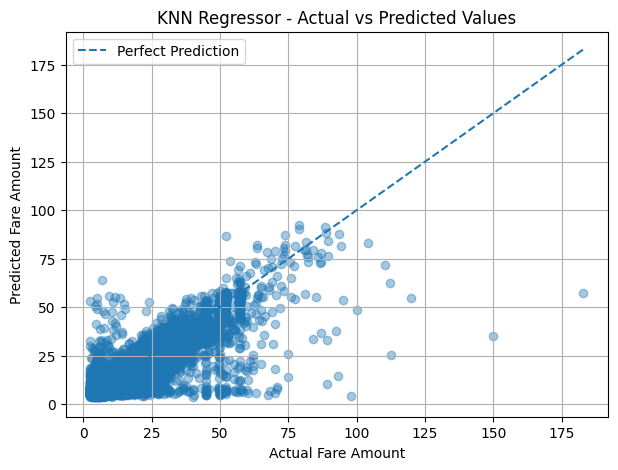

In [ ]:
# Compare actual and predicted fare amounts
comparison_df = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred_knn
})

display(comparison_df.head(10))

# Plot actual vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_knn,
    alpha=0.4
)

# Reference line
min_value = min(y_test.min(), y_pred_knn.min())
max_value = max(y_test.max(), y_pred_knn.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Fare Amount")
plt.ylabel("Predicted Fare Amount")
plt.title("KNN Regressor - Actual vs Predicted Values")
plt.legend()
plt.grid()
plt.show()


### **Conclusion – KNN Regressor**

- Achieved a Mean Absolute Error (MAE) of **2.5747**, indicating a relatively low average prediction error.
- Obtained a Mean Squared Error (MSE) of **20.7423**.
- Achieved a Root Mean Squared Error (RMSE) of **4.5544**, indicating a reasonable difference between actual and predicted fare values.
- Obtained an R² Score of **0.7759**, indicating that the model explains approximately **77.59%** of the variation in fare amounts.
- The model demonstrated good predictive performance on the test dataset.

##### **5. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement multiple linear regression and measures its performances such as MAE, MSE, RMSE, and R2. Give the conclusion statements according to the performances of the model.**

### Implementation of Multiple Linear Regression

Multiple Linear Regression is a supervised machine learning algorithm used to predict a continuous dependent variable using two or more independent variables.

It establishes a linear relationship between the target variable and multiple predictor variables.

The general equation is:

Y = b0 + b1X1 + b2X2 + ... + bnXn

Where:
- Y represents the predicted target value.
- b0 represents the intercept.
- b1, b2, ..., bn represent the coefficients.
- X1, X2, ..., Xn represent independent features.

In this implementation, Multiple Linear Regression is used to predict Uber fare amounts using pickup and drop-off coordinates, passenger count and extracted date-time features.

In [ ]:
# Initialize Multiple Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [ ]:
# Predict fare amounts for test data
y_pred_lr = linear_model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Fare Amounts:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Fare Amounts:")
print(y_pred_lr[:10])

Predictions generated successfully!

First 10 Actual Fare Amounts:
[ 4.1 14.1  3.5 11.5  8.  26.5 15.  15.  31.7  8.9]

First 10 Predicted Fare Amounts:
[ 8.3103883  16.71992945  9.70509759  9.68839922 12.13338789 16.1667245
 10.65926455 14.49085789 10.40039938  9.40507333]


In [ ]:
# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_test, y_pred_lr)

lr_mse = mean_squared_error(y_test, y_pred_lr)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(y_test, y_pred_lr)

print("MULTIPLE LINEAR REGRESSION PERFORMANCE")
print("-" * 45)

print("MAE :", round(lr_mae, 4))
print("MSE :", round(lr_mse, 4))
print("RMSE:", round(lr_rmse, 4))
print("R2 Score:", round(lr_r2, 4))

MULTIPLE LINEAR REGRESSION PERFORMANCE
---------------------------------------------
MAE : 5.0707
MSE : 65.1113
RMSE: 8.0692
R2 Score: 0.2966


,Actual Fare,Predicted Fare
0,4.1,8.310388
1,14.1,16.719929
2,3.5,9.705098
3,11.5,9.688399
4,8.0,12.133388
5,26.5,16.166725
6,15.0,10.659265
7,15.0,14.490858
8,31.7,10.400399
9,8.9,9.405073


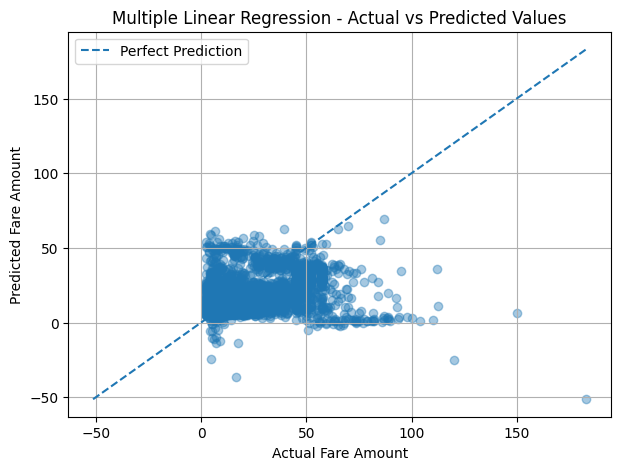

In [ ]:
# Compare actual and predicted fare amounts
comparison_df_lr = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred_lr
})

display(comparison_df_lr.head(10))

# Plot actual vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.4
)

# Reference line
min_value = min(y_test.min(), y_pred_lr.min())
max_value = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Fare Amount")
plt.ylabel("Predicted Fare Amount")
plt.title("Multiple Linear Regression - Actual vs Predicted Values")
plt.legend()
plt.grid()
plt.show()

### **Conclusion – Multiple Linear Regression**

- Achieved a Mean Absolute Error (MAE) of **5.0707**, indicating a higher average prediction error.
- Obtained a Mean Squared Error (MSE) of **65.1113**.
- Achieved a Root Mean Squared Error (RMSE) of **8.0692**, indicating larger prediction errors compared to KNN Regression.
- Obtained an R² Score of **0.2966**, indicating that the model explains approximately **29.66%** of the variation in fare amounts.
- The model demonstrated limited predictive performance, suggesting that a simple linear relationship does not adequately capture the patterns in the dataset.

In [ ]:
# Create a comparison table
regression_results = pd.DataFrame({
    'Algorithm': [
        'KNN Regressor',
        'Multiple Linear Regression'
    ],
    'MAE': [
        knn_mae,
        lr_mae
    ],
    'MSE': [
        knn_mse,
        lr_mse
    ],
    'RMSE': [
        knn_rmse,
        lr_rmse
    ],
    'R2 Score': [
        knn_r2,
        lr_r2
    ]
})

display(regression_results.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True))

,Algorithm,MAE,MSE,RMSE,R2 Score
0,KNN Regressor,2.574742,20.742301,4.554372,0.775927
1,Multiple Linear Regression,5.070731,65.111303,8.069158,0.296623



### **Overall Conclusion – Regression**

- KNN Regression and Multiple Linear Regression were successfully implemented and evaluated using the same **80:20 training-testing split**.
- Their performances were compared using MAE, MSE, RMSE, and R² Score.
- **KNN Regression** outperformed Multiple Linear Regression by achieving lower MAE, MSE, and RMSE values and a higher R² Score.
- KNN Regression explained approximately **77.59%** of the variation in fare amounts, compared to **29.66%** by Multiple Linear Regression.
- Therefore, KNN Regression proved to be the more suitable model for predicting Uber fare amounts among the two algorithms.

# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1